 # 1. โหลดข้อมูล Wisesight และสำรวจข้อมูล (EDA)

## 1.1 โหลดข้อมูล
โหลด Wisesight Sentiment จาก Hugging Face

ชุดข้อมูลแบ่งเป็น Train / Validation / Test มาให้แล้ว 

In [37]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("pythainlp/wisesight_sentiment")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['texts', 'category'],
        num_rows: 21628
    })
    validation: Dataset({
        features: ['texts', 'category'],
        num_rows: 2404
    })
    test: Dataset({
        features: ['texts', 'category'],
        num_rows: 2671
    })
})


 ## 1.2 ตรวจ label และแปลงเป็นตาราง
  - 0 = pos, 1 = neu, 2 = neg, 3 = q
  - แปลงเป็น DataFrame 
  - ตรวจจำนวนแถวและค่าที่ขาดหาย

  **ผลที่ได้:** Train 21,628 / Validation 2,404 / Test 2,671 แถว
  ไม่มี missing value

In [38]:
label_names = ds["train"].features["category"].names
print(label_names)

train = pd.DataFrame(ds["train"])
val = pd.DataFrame(ds["validation"])
test = pd.DataFrame(ds["test"])

print(train.shape, val.shape, test.shape)
print(train.isna().sum())
print(val.isna().sum())
print(test.isna().sum())

['pos', 'neu', 'neg', 'q']
(21628, 2) (2404, 2) (2671, 2)
texts       0
category    0
dtype: int64
texts       0
category    0
dtype: int64
texts       0
category    0
dtype: int64


## 1.3 ตัวอย่างข้อมูล 5 แถวแรก
หน้าตาข้อมูลเบื้องต้น มี 2 คอลัมน์ คือ `texts` (ข้อความ) และ `category`

In [39]:
train.head()

,texts,category
0,ไปจองมาแล้วนาจา Mitsubishi Attrage ได้หลังสงกร...,1
1,เปิดศักราชใหม่! นายกฯ แถลงข่าวก่อนการแข่งขันศึ...,1
2,บัตรสมาชิกลดได้อีกไหมคับ,1
3,สนใจ new mazda2ครับ,1
4,😍😍,0


## 1.4 จำนวนข้อความแต่ละประเภท
นับจำนวนข้อความของแต่ละประเภทในแต่ละชุด 

In [40]:
counts = pd.DataFrame({
    "train": train["category"].value_counts().sort_index(),
    "validation": val["category"].value_counts().sort_index(),
    "test": test["category"].value_counts().sort_index(),
})
counts.index = label_names
counts

,train,validation,test
pos,3866,434,478
neu,11795,1291,1453
neg,5491,637,683
q,476,42,57


## 1.5 สัดส่วนแต่ละประเภท (เปอร์เซ็นต์)
เทียบสัดส่วนระหว่างชุด เพราะแต่ละชุดมีจำนวนข้อความไม่เท่ากัน

**ผลที่ได้:** สัดส่วนใกล้เคียงกันทั้งสามชุด neu ประมาณ 54% และ q น้อยที่สุดประมาณ 2%

(Validation มี q เพียง 42 ข้อความ และ Test มี 57 ข้อความ ค่า F1 ของ q จึงอาจแกว่งง่าย)

In [41]:
(counts / counts.sum() * 100).round(1)

,train,validation,test
pos,17.9,18.1,17.9
neu,54.5,53.7,54.4
neg,25.4,26.5,25.6
q,2.2,1.7,2.1


## 1.6 กราฟจำนวนข้อความแต่ละประเภท
แสดงจำนวนของแต่ละประเภทเป็นกราฟแท่ง

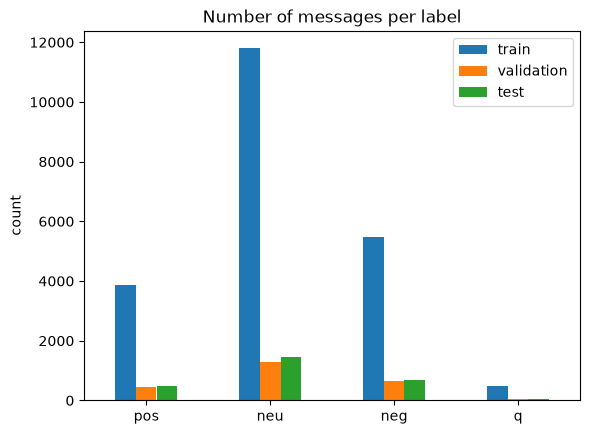

In [42]:
import matplotlib.pyplot as plt

counts.plot(kind="bar")
plt.title("Number of messages per label")
plt.ylabel("count")
plt.xticks(rotation=0)
plt.show()

 ## 1.7 ความยาวข้อความแยกตามประเภท (Train)

In [43]:
train["length"] = train["texts"].str.len()
stats = train.groupby("category")["length"].describe().round(1)
stats.index = label_names
stats

,count,mean,std,min,25%,50%,75%,max
pos,3866.0,57.2,93.2,1.0,13.0,23.0,58.0,1542.0
neu,11795.0,103.3,180.2,1.0,18.0,36.0,109.0,1997.0
neg,5491.0,87.6,102.3,1.0,30.0,59.0,110.0,1626.0
q,476.0,46.4,41.0,8.0,23.0,35.0,55.2,382.0


 **ผลที่ได้:** ค่าเฉลี่ยสูงกว่ามัธยฐานมาก แปลว่าข้อความส่วนใหญ่สั้น มีข้อความยาวไม่กี่ข้อความดึงค่าเฉลี่ยขึ้น ข้อความ q ค่อนข้างสั้น

 ## 1.8 ตรวจข้อความซ้ำ
นับข้อความซ้ำภายใน Train และข้ามชุด (Train–Validation, Train–Test, Validation–Test) เพื่อป้องกัน data leakage

In [44]:
print("ซ้ำภายใน Train:", train["texts"].duplicated().sum())
print("Validation ที่ซ้ำกับ Train:",
val["texts"].isin(train["texts"]).sum())
print("Test ที่ซ้ำกับ Train:",
test["texts"].isin(train["texts"]).sum())
print("Test ที่ซ้ำกับ Validation:",
test["texts"].isin(val["texts"]).sum())

ซ้ำภายใน Train: 16
Validation ที่ซ้ำกับ Train: 2
Test ที่ซ้ำกับ Train: 5
Test ที่ซ้ำกับ Validation: 0


**ผลที่ได้:** ซ้ำภายใน Train 16 / Validation ซ้ำกับ Train 2 / Test ซ้ำกับ Train 5 / Validation ซ้ำกับ Test 0

 ## 1.9 ดูข้อความที่ซ้ำภายใน Train

In [45]:
dup_train = train[train["texts"].duplicated(keep=False)].sort_values("texts")
dup_train[["texts", "category"]]

,texts,category
4977,toyota ผมแนะนำถ้าใครซื้ออย่าเอารถค้างสต็อคตามป...,2
9278,toyota ผมแนะนำถ้าใครซื้ออย่าเอารถค้างสต็อคตามป...,0
7008,ชุมพรมั้ยอ้ะ?!😂,3
13250,ชุมพรมั้ยอ้ะ?!😂,0
13932,ซีวิค มีส่วนลดเท่าไหร่ครับ,3
15561,ซีวิค มีส่วนลดเท่าไหร่ครับ,0
609,พรบ.คู่ชีวิตไทยนี่ถึงไหนแล้วคะ ไต้หวันไปไกลแล้...,3
8036,พรบ.คู่ชีวิตไทยนี่ถึงไหนแล้วคะ ไต้หวันไปไกลแล้...,1
17915,มันคิดเป็นหัวหรา,3
20016,มันคิดเป็นหัวหรา,0


**ผลที่ได้:** ข้อความซ้ำได้ label ต่างกัน

## 1.10 ข้อความใน Test ที่ซ้ำกับ Train
### Test
ดูแถวใน Test ที่ข้อความไปปรากฏใน Train พร้อม label ของ Test

In [46]:
test[test["texts"].isin(train["texts"])]

,texts,category
347,โลตัสกำแพงเพชร ลดมั้ยค่ะ,2
412,แล้วโปรวันพ่ออะไรค่ะ,3
895,บิ๊กซีลำพูนร่วมมั้ยคะ,3
2131,นกแอร์กับแอร์เอเชียเที่ยวบินไประนองยกเลิกมั้ยค่ะ,1
2392,หรือชัยนาทมีป่าวหว่า,0


 ### Train
ดูแถวใน Train ที่มีข้อความเดียวกันกับ 5 ข้อความข้างบน พร้อม label ของ Train เพื่อเทียบกับ label ของ Test

In [47]:
overlap = test[test["texts"].isin(train["texts"])]
train[train["texts"].isin(overlap["texts"])][["texts", "category"]].sort_values("texts")

,texts,category
3214,นกแอร์กับแอร์เอเชียเที่ยวบินไประนองยกเลิกมั้ยค่ะ,3
6542,บิ๊กซีลำพูนร่วมมั้ยคะ,1
6946,หรือชัยนาทมีป่าวหว่า,3
18395,แล้วโปรวันพ่ออะไรค่ะ,0
8605,โลตัสกำแพงเพชร ลดมั้ยค่ะ,3


**ผลที่ได้:** label ของข้อความเดียวกันไม่ตรงกันทั้ง 5 ข้อความ(เช่น "บิ๊กซีลำพูนร่วมมั้ยคะ" Train เป็น 1 แต่ Test เป็น 3)

หมายความว่า ป้ายกำกับของ Wisesight โดยเฉพาะ q กับประเภทอื่น มีความกำกวม

## 1.11 ข้อความที่สั้นที่สุด

ดู 15 ข้อความที่สั้นที่สุดใน Train
เรียงตามจำนวนตัวอักษรจากน้อยไปมาก

**ผลที่ได้:** 
- ทั้ง 15 ข้อความเป็นอีโมจิตัวเดียว (ความยาว 1 ตัวอักษร)
- ไม่มีข้อความว่าง
- ป้ายกำกับผสมกัน (pos, neu, neg)
- ข้อความที่ยาว 1 ตัวอักษรมีมากกว่า 15 ข้อความ ตารางนี้เป็นเพียง 15 แถวแรก
- ไม่ลบอีโมจิตอนทำความสะอาดข้อความ เพราะบางข้อความจะกลายเป็นข้อความว่าง

In [48]:
train.sort_values("length").head(15)[["texts", "category", "length"]]

,texts,category,length
3482,😗,1,1
15317,😌,1,1
17140,😍,0,1
5794,😔,2,1
8123,🍾,1,1
20168,🤔,1,1
5151,🤤,0,1
21077,🧐,1,1
7936,😒,1,1
20837,🤪,0,1


## 1.12 ข้อความซ้ำใน Train ที่ label ไม่ตรงกัน
นับแถวที่ข้อความเดียวกันมีมากกว่า 1 label

**ผลที่ได้:** label ไม่ตรงกัน 32 แถว แถวที่ซ้ำแต่ label ตรงกัน 0 แถว

In [49]:
conflict = train.groupby("texts")["category"].transform("nunique") > 1
print("แถวที่ข้อความซ้ำและป้ายขัดกัน:", conflict.sum())
print("แถวที่ซ้ำแต่ป้ายตรงกัน:", (train["texts"].duplicated(keep=False) & ~conflict).sum())

แถวที่ข้อความซ้ำและป้ายขัดกัน: 32
แถวที่ซ้ำแต่ป้ายตรงกัน: 0


## 1.13 ทำความสะอาดข้อความซ้ำ (ลบจาก Train)
ลบแถวใน Train ที่
1. ข้อความอยู่ใน Validation หรือ Test
2. ข้อความซ้ำและป้ายกำกับขัดกัน

**ไม่แตะ** Validation และ Test ผลเก็บในตาราง `train_clean`

**ผลที่ได้:** Train 21,628 → 21,589 แถว (ลบไป 39 แถว)

In [50]:
eval_texts = list(val["texts"]) + list(test["texts"])

drop_eval = train[train["texts"].isin(eval_texts)].index
drop_conflict = train[conflict].index

train_clean = train.drop(list(drop_eval) + list(drop_conflict))
print("Train เดิม:", len(train), " หลังลบ:", len(train_clean), "ลบไป:", len(train) - len(train_clean))

Train เดิม: 21628  หลังลบ: 21589 ลบไป: 39


## 1.14 ตรวจผลหลังลบ
เช็กว่า `train_clean` ไม่มีข้อความของ Validation และ Test เหลืออยู่ และดูจำนวนแต่ละประเภทหลังลบ

In [51]:
print(train_clean["texts"].isin(val["texts"]).sum(), train_clean["texts"].isin(test["texts"]).sum())
train_clean["category"].value_counts().sort_index()

0 0


category
0     3853
1    11790
2     5489
3      457
Name: count, dtype: int64

## 1.15 เทียบจำนวนก่อนและหลังลบ

**ผลที่ได้:** pos ลบ 13 / neu ลบ 5 / neg ลบ 2 / q ลบ 19

q ถูกลบสัดส่วนมากสุด (19 จาก 476 ข้อความ ประมาณ 4%) และเป็นประมาณครึ่งหนึ่งของแถวที่ลบทั้งหมด (19 จาก 39 แถว)

In [52]:
before = train["category"].value_counts().sort_index()
after = train_clean["category"].value_counts().sort_index()

compare = pd.DataFrame({"ก่อนลบ": before, "หลังลบ": after})
compare["ลบไป"] = compare["ก่อนลบ"] - compare["หลังลบ"]
compare.index = label_names
compare

,ก่อนลบ,หลังลบ,ลบไป
pos,3866,3853,13
neu,11795,11790,5
neg,5491,5489,2
q,476,457,19



## 1.16 ตัวอย่างข้อความแต่ละประเภท
สุ่มดูประเภทละ 3 ข้อความ (ตั้ง `random_state=42` เพื่อให้ได้ชุดเดิมทุกครั้ง)

**ข้อสังเกต:** มี URL, ตัวอักษรซ้ำ, คำแสลง, คำพิมพ์ผิด และภาษาไทยปนอังกฤษ
บางข้อความ q ไม่มีเครื่องหมาย `?`

In [53]:
for lab in range(4):
    print(label_names[lab])
    for t in train_clean[train_clean["category"] ==
lab]["texts"].sample(3, random_state=42):
        print("-", t)
    print()

pos
- เหลือรอลุ้นคำตอบอีก 1 ราย 😥
- กินตัวนี้เพิ่มอีกนิดไป 100 pipers ดีกว่าครับ คหสต จากคนแดกเหล้าทุกคืนวัน
- พุธและ ป่ะๆๆๆ

neu
- สำหรับ Toyota Hilux Revo Rocco จะเป็น 2.8 ทั้งหมดครับ https://www.toyota.co.th/hiluxrevo/#/rocco/lineup
- เคยเจอไหม มิตรสหายที่อะไรๆ ญี่ปุ่นก็ดีไปหมด ขนาดห้องน้ำหนาวยัง romanticise ได้ โอเค เราชอบอยู่ญี่ปุ่นมากกว่าไทยนะ แต่อะไรไม่ดีเราก็ว่าไม่ดี อย่างฝรั่งเศสที่เราชอบๆ มันยังมีเรื่องที่เราไม่ชอบ เช่น ขี้หมาเยอะ
- แบรนด์ Sephora ค่า

neg
- กินแต่ละสาขา บริการของพนักงานแย่มาก กินที่เซ็นทรัลแจ้ง พนักงานเดินไปเดินมา สั่งหมูไปรอจนกินบนเตาหมดเกลี้ยงยังไม่มา จนต้องเรียกมาถาม ถามเสร็จหายไปอีกร่วม 10 นาที ออกมาวางปุ๊บ เดินสะบัดก้นไปปั๊บ สาขาอิมพีเรียลสำโรง ขอที่คีบตอบกลับมาว่าไม่มี เออ ดีแฮะ มาตรฐานแต่ละที่ไม่เหมือนกันดี ตะเกียบก็ไหลลื่นดีเหลือเกิน บังคับคีบจนนิ้วจะเป็นตะคริว นานๆเข้ากินที นึกว่าบริการจะดีขึ้น หึหึ ห่วยเหมือนเดิม
- แพ้ kiehl's แบบไม่น่าให้อภัย ปกติหน้านี่กระแดะมากเว่อชอบของแพง ใช้ของแพงนี่ไม่เคยเป็นไรจ้า อิเวนแพ้คีลส์ทุกตัวใช้ละ…
- ค้นพบแล้วว่าแดก2

## 1.17 สุ่มอ่านตัวอย่างแต่ละประเภท
สุ่มอ่านประเภทละ 20 ข้อความ

In [54]:
for lab in range(4):
    print(label_names[lab])
    for t in train_clean[train_clean["category"] ==
lab]["texts"].sample(20, random_state=1):
        print("-", t)
    print()

pos
- เค้าชอบ MG3
- สวยจังแต่ข่อยใช้รีโว่นะก้อประหยัดค่าน้ำมันดี
- ได้หมด ถ้าคนน้อยก้อฮอทพอท
- กินป่าว
- สิ้นปี
- เปลี่ยนๆๆขอโฮการ์เด้น 55555
- 285.กินไห้เมาไห้ลืมคนอย่างเธอ แค่ความ.รัก ควาย ควาย
- เอาตรงๆ รสชาติสู้เหล้าแพงๆได้อยู่นะ งบน้อยก็จะจัด royal stag นี่แหละ
- MKกับฮอตพอตน่าทำนะ
- รวมกลุ่มกินบาบีก้อนตอน60
- อยากกินอ่ะหมู 😣😣😣
- ถ้าไม่มีเรนเจอร์โมเดลปี2012 ฟอร์ดประเทศไทยจบเห่ไปแล้ว
- ขอดูดีแม๊กด้วยคับ
- เช
- พาไปกินหน่อยยย
- นัดวันที
- เรื่องกินนี่ไม่เคยปฏิเสธกันเลยยยยยยย 5555555
- แทกเฉยๆ
- โรงแรมขนาดเล็ก ห้องพักสะดวกสบาย ราคาประหยัด
- ขอดูรายละเอียดนิสสันอะเมร่าหน่อยคับ ผ่อนเดือนละกี่บาท

neu
- นี่ข้อร้องเรียนเมื่อปี 2015 ฮะพี่ก้อน...😨
- สำหรับผมไม่มีทางตั้งแต่หันมาเวฟผมเหม็นบุหรี่มวนไปเลยเหม็นมากๆครับ
- อ้าวหรอ
- ก้อนขอน้อมรับ คำติ/ชม เพื่อนำไปปรับปรุง ข้าวผัดกระเทียมของก้อนให้ดียิ่งขึ้นครับ
- ก็บาร์บีกอนคัดสรรงัย 😁😍
- ไหนบอกจะประหยัดเงินไงจ้ะ 555
- มากินมั้ยซื้อมายังไม่ได้กินเลย
- พระจันทร์ก็ยังคงอยู่ที่เดิม แค่มองไม่เห็นบางเวลา เหมือนคนที่บางทีไม่ได้เจอกัน...แต่เขาก็ยังอยู่ใ

## สรุปขั้นที่ 1

**ข้อมูล**
- โหลด Wisesight Sentiment จาก Hugging Face: Train 21,628 /Validation 2,404 / Test 2,671 ข้อความ
- ไม่มี missing value
- ใช้การแบ่ง Train / Validation / Test ที่มากับชุดข้อมูล ไม่ได้แบ่งเอง

**การกระจายของประเภท**
- สัดส่วนของแต่ละประเภทใกล้เคียงกันทั้งสามชุด โดย neu ประมาณ 54%, neg ประมาณ 25–26%, pos ประมาณ 18%
- q น้อยที่สุด ประมาณ 2% (Train 476, Validation 42, Test 57 ข้อความ)
- จำนวนใน Validation และ Test น้อย F1 ของ q จึงอาจแกว่งง่าย

**ข้อความซ้ำและการทำความสะอาด**
- ตรวจพบข้อความซ้ำ ภายใน Train 16, Validation ซ้ำกับ Train 2, Test ซ้ำกับ Train 5
- ข้อความซ้ำที่ตรวจแล้วมี label ไม่ตรงกัน (ใน Train และ Test)
- ลบจาก Train เท่านั้น ได้แก่ แถวที่ข้อความอยู่ใน Validation/Test และแถวที่ซ้ำกันเองแต่ label ขัดกัน ไม่แตะ Validation และ Test
- Train 21,628 → 21,589 แถว (ลบ 39 แถว)
- q ถูกลบสัดส่วนมากที่สุด (19 จาก 476 ข้อความ ประมาณ 4%)

**ลักษณะข้อความ**
- ข้อความส่วนใหญ่สั้น (มัธยฐานของความยาว: pos 23, neu 36, neg 59, q 35 ตัวอักษร)
ค่าเฉลี่ยสูงกว่ามัธยฐานเพราะมีข้อความยาวบางส่วนดึงค่าเฉลี่ยขึ้น
- ข้อความที่สั้นที่สุดเป็นอีโมจิตัวเดียว จึงไม่ควรลบอีโมจิตอนทำความสะอาด
- ตัวอย่างข้อความมี URL ตัวอักษรซ้ำ คำแสลง คำพิมพ์ผิด และภาษาไทยปนอังกฤษ
- บางข้อความ q ไม่มีเครื่องหมาย `?`

**ข้อสังเกตและข้อจำกัด**
-  label ของข้อความเดียวกันไม่ตรงกันในข้อความซ้ำที่ตรวจแล้ว สะท้อนว่า label ของ Wisesight โดยเฉพาะ q กับประเภทอื่น มีความกำกวม